# Google tunable coupler: a 2 × 2 lattice (four qubits, four couplers), a Quantcore-PDK rebuild, step by step

**What the chip is.** The smallest closed plaquette of Sycamore's coupler lattice: four flux-tunable Xmon-type
transmons on the corners of a square, a flux-tunable transmon coupler on each of the four bonds (Yan et al., PR Applied
10, 054062 (2018); Arute et al., Nature 574, 505 (2019)). Every qubit has a λ/4 readout, an XY line and a Z line; every
coupler a Z line. It is the cell of `google_tc_cell` (same qubit, coupler, junctions and coupling geometry) tiled round
a square.

**This notebook rebuilds the plaquette in the Quantcore PDK; it is not a replica** (spec
`docs/designs/google/google_tc_2x2.md`): Quantum Metal `TransmonCrossFL` crosses with **Quantcore trilayer SQUIDs**
(PDK junction rule), Quantcore `BondPad`s, qcc routes and a KQC airbridge where a coupler's Z line crosses a feedline,
the PDK die frame (10 × 10 mm, QCT), sapphire 650 µm (εr 10.25), and the qcc LOM.

| | from the source | adapted here (why) |
|---|---|---|
| lattice | square grid, a coupler on every nearest-neighbour bond (Sycamore: 54 qubits, 88 couplers, diagonal array) | the 2 × 2 plaquette, axis-aligned |
| qubits, coupler, couplings | as `google_tc_cell` (Sycamore SI Table 2, §I; Yan Fig. 2, Eq. 5) | the same cross sizes, SQUIDs, end-on gaps and `d.couple` estimates |
| idle frequencies | Sycamore idles neighbours apart | checkerboard: Q00 / Q11 at the design L_J, Q10 / Q01 detuned by L_J (LOM only) |
| readout | 9 groups of 6 qubits on Purcell-filtered lines | two feedlines (left: Q00, Q01; right: Q10, Q11), λ/4 hangers at 4.56 … 4.68 GHz, no Purcell filter |
| wiring | flip-chip wiring die, bump bonds | planar: the two side couplers' Z lines cross the feedlines on airbridges |
| junctions | Al/AlOx SQUIDs (not given) | Quantcore Nb/AlOx/Nb trilayer SQUIDs (PDK rule: Δ 1.4 meV, R_n 40–50 kΩ) |
| pads | (no layout) | **PDK pad rule**: 16 bond pads, each etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | the plaquette sits at the die centre (checked in Design 8) |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** Papers cited for parameters only; the layout and code are ours (GPL, as the repository).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die, the sixteen bond pads, the two feedlines, the four qubit crosses with their trilayer
SQUIDs, their λ/4 hanger readouts, the four coupler crosses with the declared coupling capacitances, the XY and Z
control lines (two of them on airbridges over the feedlines), and then the whole chip (the centring check, the targets
and sim groups, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `google_tc_2x2.v1.ipynb`; both save the same
`google_tc_2x2.json`.

## Setup

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers. `LIVE`
follows `QCC_LIVE` (live KLayout, or headless snapshots with `QCC_LIVE=0`).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj
from quantcore_circuits.lom import estimates as est
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/google")
EPS = est.substrate_eps(get_pdk())               # sapphire, εr 10.25

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on; the library applies each of them (frame and cheese in the build, the pad rule
through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings).

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## The source targets and the readout plan

**Source targets** (Arute et al. 2019, SI Table 2 and §I), the readout plan (staggered round Sycamore's median) and the
λ/4 lengths, set for those frequencies with the LOM.

In [5]:
SRC = {"f_q_idle_GHz": 6.661, "alpha_MHz": -208.0, "f_r_GHz": 4.618, "kappa_MHz": 0.64, "g_on_MHz": -20.0}
F_R = {"Q00": 4.56, "Q01": 4.60, "Q10": 4.64, "Q11": 4.68}           # staggered readouts around 4.618 GHz
L_READ = {"Q00": 6243, "Q01": 6182, "Q10": 6122, "Q11": 6064}       # λ/4 lengths, set for F_R with the LOM

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedlines are drawn as soon as
their pads exist (segment 3), the readouts once the qubits are there (segment 5) and the control lines once their ends
are (segment 7). Every position is fixed by `M`, the cross geometry and the plan constants, so the order changes
nothing.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with its frame; `M(sx, sy)` mirrors the bottom-left quadrant round the plaquette |
| 2 | sixteen bond pads: four for the feedlines, an XY and a Z pad per qubit, a Z pad per coupler |
| 3 | the readout line: the two vertical feedlines, left (Q00, Q01) and right (Q10, Q11) |
| 4 | the four qubit crosses (`TransmonCrossFL`) with their trilayer SQUIDs and readout claws |
| 5 | the four λ/4 hanger readouts, 900 µm coupled to their feedline |
| 6 | the coupling: a coupler cross on every bond and the declared coupling capacitances |
| 7 | the control routing: the XY ends with their lines, the qubits' and couplers' Z lines (two on airbridges) |
| 8 | the whole chip: the centring check, the targets and sim groups, the save |

## Design 1 · The die and its frame

A 10 × 10 mm die: the plaquette needs sixteen pads. The build draws the PDK frame (dicing L's, alignment grids, chip
boundary, the device ID `GTC4Q` on a free edge).

The layout is written for the bottom-left quadrant and mirrored: `M(sx, sy)` maps a bottom-left point into the
quadrant (sx, sy) = (±1, ±1) round the plaquette centre (X0, Y0).

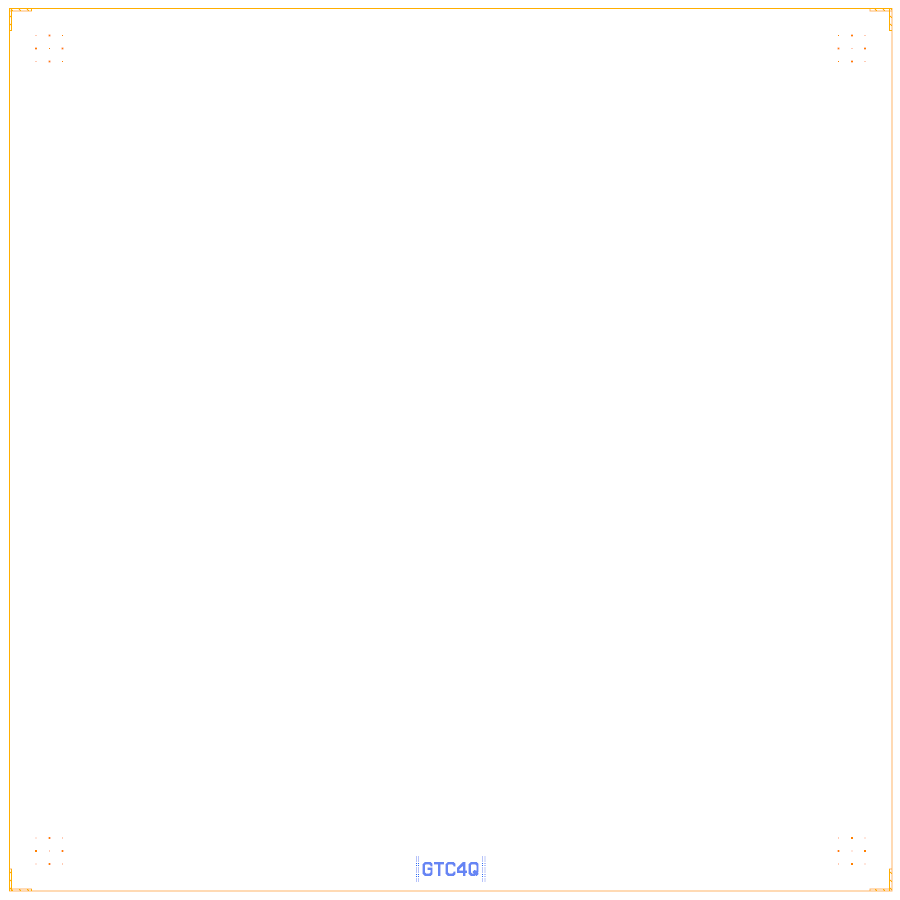

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/google/google_tc_2x2_die.png')

In [6]:
W = H = 10000
X0 = Y0 = 5000
M = lambda sx, sy: (lambda x, y: (X0 - sx * (x - X0), Y0 - sy * (y - Y0)))   # bottom-left quadrant → (sx, sy)
d = Designer("google_tc_2x2", box=(0, 0, W, H), chip={"name_chip": "GTC4Q"}, live=LIVE)
layout_step(d, OUT / "google_tc_2x2_die.png", size=(900, 900), width=320)

## Design 2 · Bond pads: the PDK pad rule

Sixteen `BondPad`s: the two feedlines' four (side edges), an XY and a Z pad per qubit (top and bottom edges), and a Z
pad per coupler (the bottom / top couplers on those edges, the left / right couplers on the side edges, at the
plaquette's height). The PDK puts each pad's outer etch edge **`frame.pad_edge` = 100 µm from the die edge**: `edge="auto"` slides it
perpendicular to its nearest edge until that holds (its position along the edge is kept).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FLL_in | `BondPad` | w | 100.0 | ✓ |
| FLL_out | `BondPad` | w | 100.0 | ✓ |
| FLR_in | `BondPad` | e | 100.0 | ✓ |
| FLR_out | `BondPad` | e | 100.0 | ✓ |
| XY_Q00 | `BondPad` | s | 100.0 | ✓ |
| Z_Q00 | `BondPad` | s | 100.0 | ✓ |
| XY_Q10 | `BondPad` | s | 100.0 | ✓ |
| Z_Q10 | `BondPad` | s | 100.0 | ✓ |
| XY_Q01 | `BondPad` | n | 100.0 | ✓ |
| Z_Q01 | `BondPad` | n | 100.0 | ✓ |
| XY_Q11 | `BondPad` | n | 100.0 | ✓ |
| Z_Q11 | `BondPad` | n | 100.0 | ✓ |
| Z_CB | `BondPad` | s | 100.0 | ✓ |
| Z_CT | `BondPad` | n | 100.0 | ✓ |
| Z_CL | `BondPad` | w | 100.0 | ✓ |
| Z_CR | `BondPad` | e | 100.0 | ✓ |

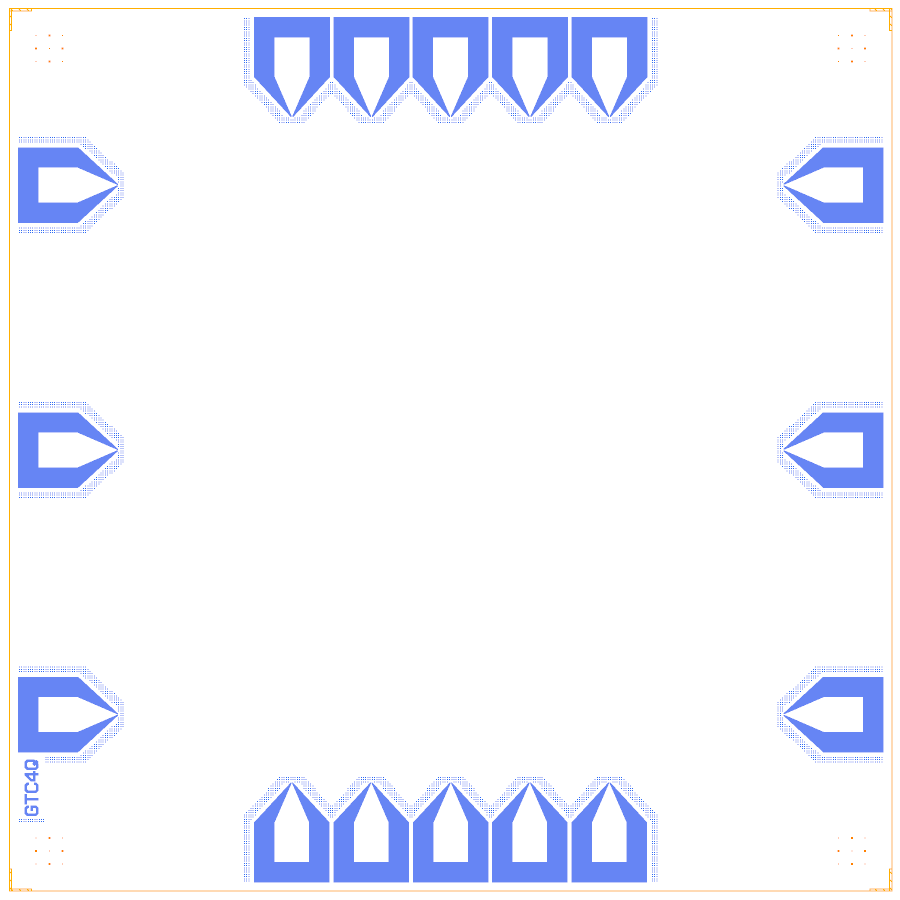

**On the chip so far:** 16 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 16 component(s) `FLL_in`, `FLL_out`, `FLR_in`, `FLR_out`, `XY_Q00`, `Z_Q00`, `XY_Q10`, `Z_Q10` … (+8).

WindowsPath('examples/designs/google/google_tc_2x2_pads.png')

In [7]:
QUBITS = {"Q00": (-1, -1), "Q10": (1, -1), "Q01": (-1, 1), "Q11": (1, 1)}
LQ, WQ, GQ = 160, 30, 30                         # qubit cross (µm)
LC, WC, GC = 70, 20, 20                          # coupler cross
GAP = 100                                        # arm tip ↔ arm tip
S = LQ + GAP + LC                                # qubit ↔ coupler pitch; qubit pitch 2S
# bonds: coupler name → (qubit a, qubit b, centre, rotation: its SQUID arm points out of the plaquette)
BONDS = {"CB": ("Q00", "Q10", (X0, Y0 - S), 0), "CT": ("Q01", "Q11", (X0, Y0 + S), 180),
         "CL": ("Q00", "Q01", (X0 - S, Y0), -90), "CR": ("Q10", "Q11", (X0 + S, Y0), 90)}
pads = {}
pad = lambda n, xy, r: pads.setdefault(n, d.add(n, "BondPad", at=xy, rot=r, edge="auto"))
for side, sx in (("L", -1), ("R", 1)):
    m = M(sx, -1)
    pad(f"FL{side}_in", m(1150, 2000), -90 if sx < 0 else 90)
    pad(f"FL{side}_out", m(1150, 8000), -90 if sx < 0 else 90)
for name, (sx, sy) in QUBITS.items():
    m = M(sx, sy)
    pad(f"XY_{name}", m(3200, 1150), 0 if sy < 0 else 180)
    pad(f"Z_{name}", m(4100, 1150), 0 if sy < 0 else 180)
for name, (qa, qb, (x, y), rot) in BONDS.items():
    if name in ("CB", "CT"):
        pad(f"Z_{name}", (x, 1150 if name == "CB" else H - 1150), 0 if name == "CB" else 180)
    else:
        pad(f"Z_{name}", M(-1 if name == "CL" else 1, -1)(1150, Y0), -90 if name == "CL" else 90)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "google_tc_2x2_pads.png", size=(900, 900), width=320)

## Design 3 · Readout: the two feedlines

- **Feedlines:** left (Q00, Q01) and right (Q10, Q11), vertical at x = `XF` / W − `XF`, between their side pads. They need no qubit, so they come
first; each pair of readouts will hang on its line (Design 5).

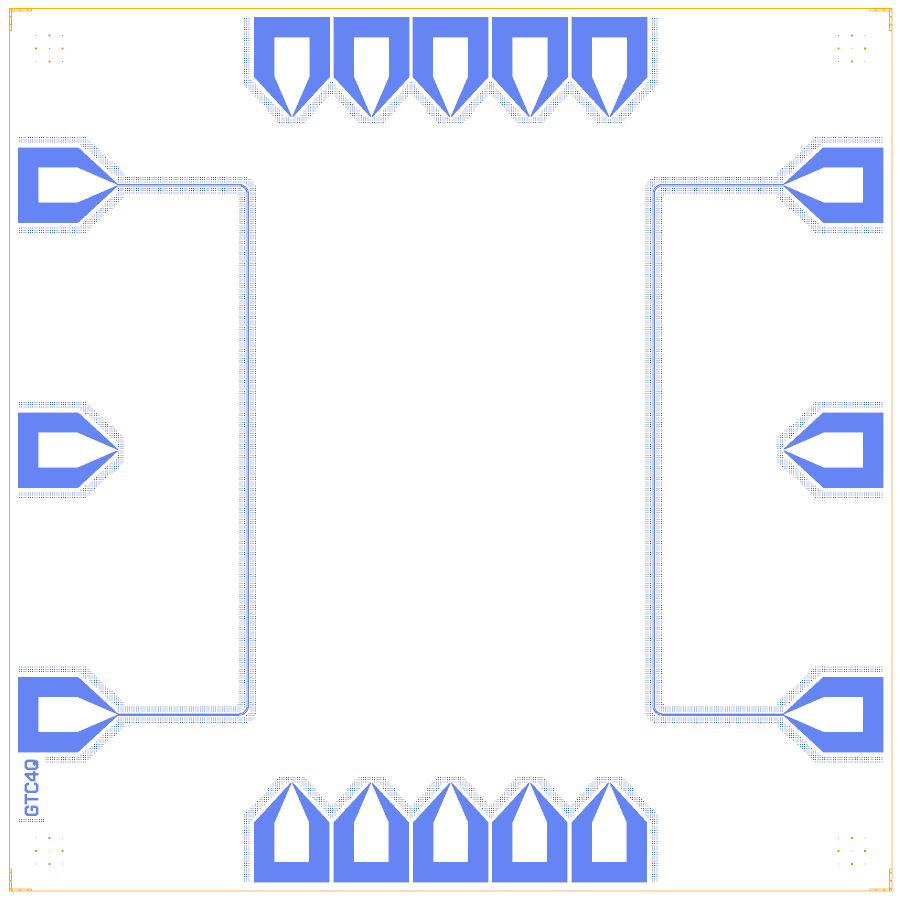

**On the chip so far:** 16 pads · 0 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 2 route(s) `FLL`, `FLR`.

WindowsPath('examples/designs/google/google_tc_2x2_s3_feedlines.png')

In [8]:
XF = 2700                                        # left feedline (the right one at W − XF)
fl = {}
for side, sx in (("L", -1), ("R", 1)):
    m = M(sx, -1)
    fl[side] = d.route(f"FL{side}", pads[f"FL{side}_in"].a, pads[f"FL{side}_out"].a, r=100,
                       nodes=[m(XF, 2000), m(XF, 8000)])
layout_step(d, OUT / "google_tc_2x2_s3_feedlines.png", size=(900, 900), width=320)

## Design 4 · Qubit placement: four Xmon crosses with trilayer SQUIDs

**Junctions.** As in `google_tc_cell`: a Quantcore trilayer SQUID drawn for L_J = 6.1 nH at zero flux in every qubit
and coupler (parallel R_n ≈ 40 kΩ, the low end of the PDK window). The DRC's `pdk_rn` judges the device, the SQUID's two
junctions in parallel (each ≈ 80 kΩ), so these SQUIDs are inside the window and raise no warning.

In [9]:
QJ_PARAMS, QJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)   # R_n ≈ 40 kΩ (PDK window)
CJ_PARAMS, CJ = trilayer_junction("metal:TransmonCrossFL", lj_nH=6.1, squid=True)
print("SQUID (drawn, zero flux):", QJ, f"→ parallel R_n {rn_from_lj(QJ['Lj_nH']) / 1e3:.1f} kΩ")

SQUID (drawn, zero flux): {'Lj_nH': 6.0129, 'Cj_fF': 16.8} → parallel R_n 40.2 kΩ


**Qubits and couplers.** Each qubit's SQUID arm (its local south) points away from the plaquette in y and its readout
claw away in x (the couplers, Design 6, point their SQUID arms out of the plaquette too). The claw stops short of the cross's side arms.

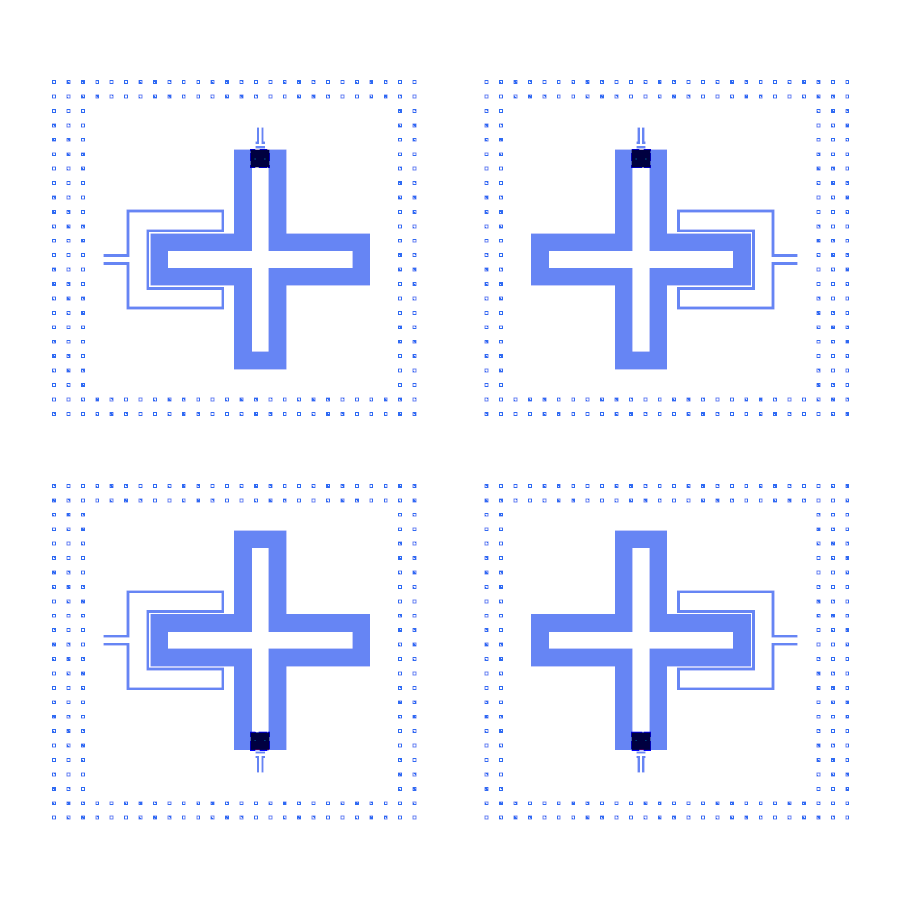

**On the chip so far:** 16 pads · 4 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 4 component(s) `Q00`, `Q10`, `Q01`, `Q11`.

WindowsPath('examples/designs/google/google_tc_2x2_s4_qubits.png')

In [10]:
CLAW = dict(connector_type="0", claw_length=130, ground_spacing=3, claw_width=30, claw_gap=4)
q, tc = {}, {}
for name, (sx, sy) in QUBITS.items():
    rot = 0 if sy < 0 else 180
    claw_at = {(-1, 0): "0", (1, 0): "180", (-1, 180): "180", (1, 180): "0"}[(sx, rot)]   # Metal: "0" = west
    q[name] = d.add(name, "metal:TransmonCrossFL", at=(X0 + sx * S, Y0 + sy * S), rot=rot, junction=QJ,
                    cross_length=LQ, cross_width=WQ, cross_gap=GQ,
                    connection_pads={"readout": {**CLAW, "connector_location": claw_at}}, **QJ_PARAMS)
layout_step(d, OUT / "google_tc_2x2_s4_qubits.png", box=(X0 - S - 450, Y0 - S - 450, X0 + S + 450, Y0 + S + 450),
            size=(900, 900), width=360)

## Design 5 · Readout: four λ/4 hangers

- **Readouts:** λ/4 from each claw, out in x then along a vertical run (the meander) into a 900 µm **hanger** on its
  feedline, shorted at its end; `fl.hanger(near=(x, y))` centres the coupler at the feedline point nearest (x, y)
  (`Y_HANG` on the vertical run): given by position, not by arclength from the pad, it stays put when the pads (and so
  the feedline's start) move, and each readout's last leg meets its coupler square. Each length is longer than its path
(out in x, then the vertical run), so the router puts the leftover into one KQC `Meander` on the vertical run.

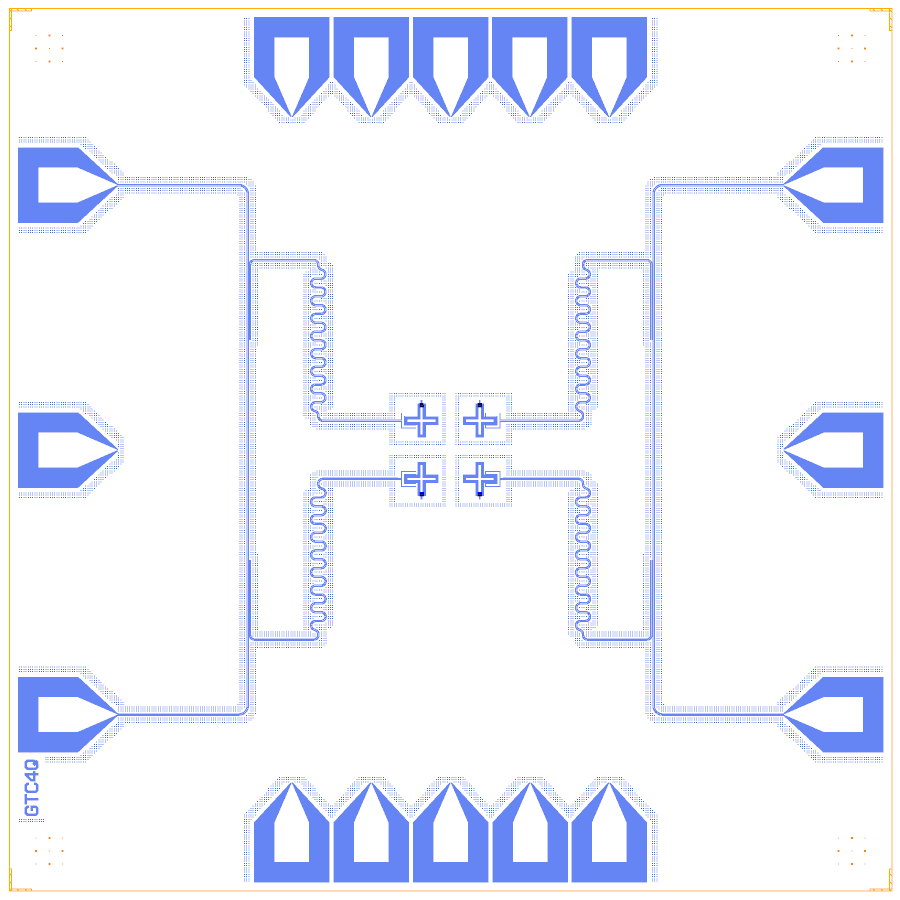

**On the chip so far:** 16 pads · 4 qubits · 0 other components · 6 routes · 0 declared couplings. **This step added** 4 route(s) `R_Q00`, `R_Q10`, `R_Q01`, `R_Q11`.

WindowsPath('examples/designs/google/google_tc_2x2_s5_readouts.png')

In [11]:
K_LEN = 900                                      # hanger coupling length
Y_HANG = {"Q00": 3300, "Q01": 6700, "Q10": 3300, "Q11": 6700}       # hanger centres on the vertical feedlines
for name, (sx, sy) in QUBITS.items():
    m = M(sx, sy)
    side = "L" if sx < 0 else "R"
    yh = Y_HANG[name]
    y_start = yh - K_LEN / 2 if sy < 0 else yh + K_LEN / 2          # the coupler starts on the lattice side
    hang = fl[side].hanger(near=(XF if sx < 0 else W - XF, yh), length=K_LEN, side="right" if sx < 0 else "left", ground_gap=4, end="short",
                           direction="forward" if sy < 0 else "backward")
    xr = m(3500, Y0)[0]                                              # the readout's vertical run (meander)
    d.route(f"R_{name}", q[name].readout, hang, meander=L_READ[name], r=50, nodes=[(xr, Y0 + sy * S), (xr, y_start)])
layout_step(d, OUT / "google_tc_2x2_s5_readouts.png", size=(900, 900), width=320)

## Design 6 · Coupling: four coupler crosses and the declared capacitances

**The couplers** `CB`, `CT`, `CL`, `CR`: a smaller cross (70 µm arms, the same trilayer SQUID as the qubits, Design 4)
on every bond, its arm tips facing the two qubits' across the 100 µm gap, its SQUID arm pointing out of the plaquette
(the cell of `google_tc_cell`, tiled round the square).

**Couplings no route carries** (coplanar-strip estimates, replaced by the `plaquette` Q3D job): qubit ↔ coupler on
every bond, the direct qubit ↔ qubit capacitance across every coupler (screened), and the two diagonals across the
plaquette.

C(Q ↔ C) ≈ 2.35 fF, C(Q ↔ Q, bond) ≈ 0.282 fF, C(Q ↔ Q, diagonal) ≈ 0.08 fF


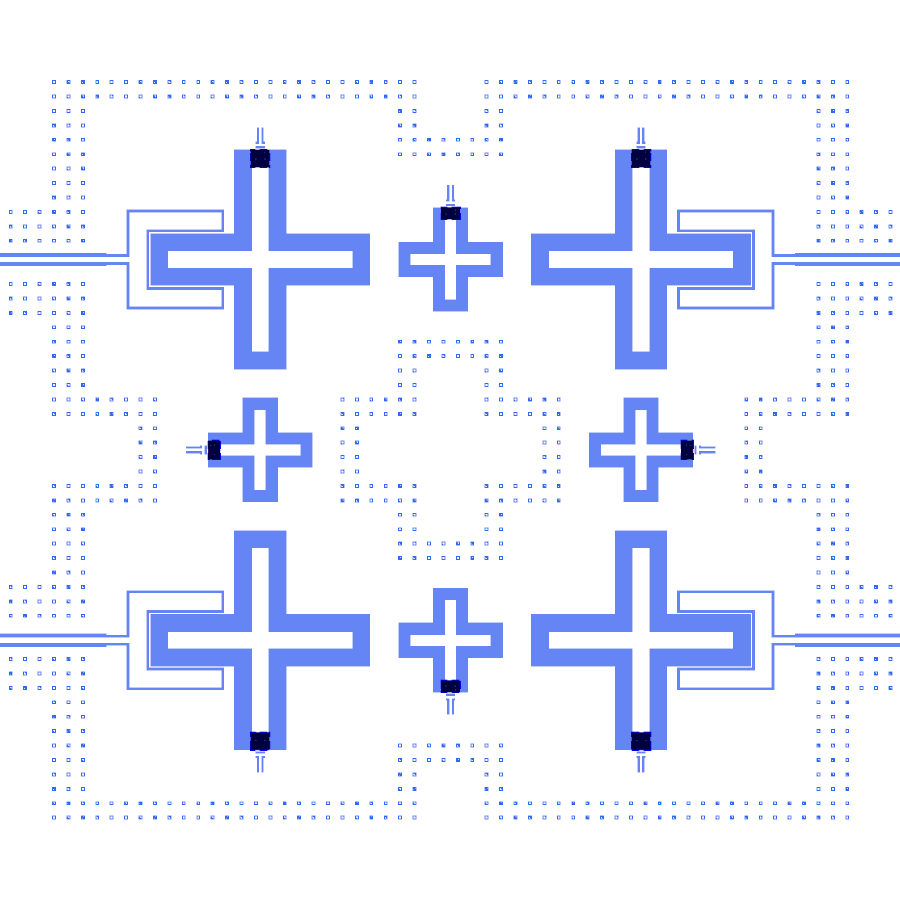

**On the chip so far:** 16 pads · 8 qubits · 0 other components · 6 routes · 14 declared couplings. **This step added** 4 component(s) `CB`, `CT`, `CL`, `CR`.

WindowsPath('examples/designs/google/google_tc_2x2_components.png')

In [12]:
for name, (qa, qb, xy, rot) in BONDS.items():
    tc[name] = d.add(name, "metal:TransmonCrossFL", at=xy, rot=rot, junction=CJ, cross_length=LC, cross_width=WC,
                     cross_gap=GC, connection_pads={}, **CJ_PARAMS)
C_QC = round(est.coplanar_coupling(WQ, LQ, LC, GAP, EPS), 2)
C_QQ = round(est.coplanar_coupling(WQ, LQ, LQ, 2 * GAP + 2 * LC, EPS, screening=0.15), 3)
C_DIAG = round(est.coplanar_coupling(WQ, LQ, LQ, 2 * math.sqrt(2) * S - 2 * LQ, EPS, screening=0.05), 3)
print(f"C(Q ↔ C) ≈ {C_QC} fF, C(Q ↔ Q, bond) ≈ {C_QQ} fF, C(Q ↔ Q, diagonal) ≈ {C_DIAG} fF")
for name, (qa, qb, _, _) in BONDS.items():
    d.couple(f"Cg_{qa}_{name}", qa, name, C_fF=C_QC, note="qubit arm tip ↔ coupler arm tip, 100 µm (CPS)")
    d.couple(f"Cg_{name}_{qb}", name, qb, C_fF=C_QC, note="coupler arm tip ↔ qubit arm tip, 100 µm (CPS)")
    d.couple(f"Cg_{qa}_{qb}", qa, qb, C_fF=C_QQ, note="qubit ↔ qubit across the coupler (CPS, screening 0.15)")
d.couple("Cg_Q00_Q11", "Q00", "Q11", C_fF=C_DIAG, note="diagonal, across the plaquette (CPS, screening 0.05)")
d.couple("Cg_Q10_Q01", "Q10", "Q01", C_fF=C_DIAG, note="diagonal, across the plaquette (CPS, screening 0.05)")
layout_step(d, OUT / "google_tc_2x2_components.png", box=(X0 - S - 450, Y0 - S - 450, X0 + S + 450, Y0 + S + 450),
            size=(900, 900), width=360)

## Design 7 · Routing: the XY and Z lines

**XY ends:** an open CPW end at each qubit's outer diagonal, the drive lines' targets.

- **XY lines:** from the XY pad round the outside of the plaquette to the open end at the qubit's outer diagonal.
- **Z lines:** each qubit's flux T-line to its pad; the bottom / top couplers straight down / up; the left / right
  couplers' lines cross the feedline on an **airbridge** (`d.waypoint(..., airbridge=True)`).

{'FLL': 8864.2, 'FLR': 8864.2, 'R_Q00': 6243.0, 'R_Q10': 6122.0, 'R_Q01': 6182.0, 'R_Q11': 6064.0, 'XY_Q00_line': 4549.2, 'Z_Q00_line': 3743.6, 'XY_Q10_line': 4549.2, 'Z_Q10_line': 3743.6, 'XY_Q01_line': 4549.2, 'Z_Q01_line': 3743.6, 'XY_Q11_line': 4549.2, 'Z_Q11_line': 3743.6, 'Z_CB_line': 3316.5, 'Z_CT_line': 3316.5, 'Z_CL_line': 3316.5, 'Z_CR_line': 3316.5}


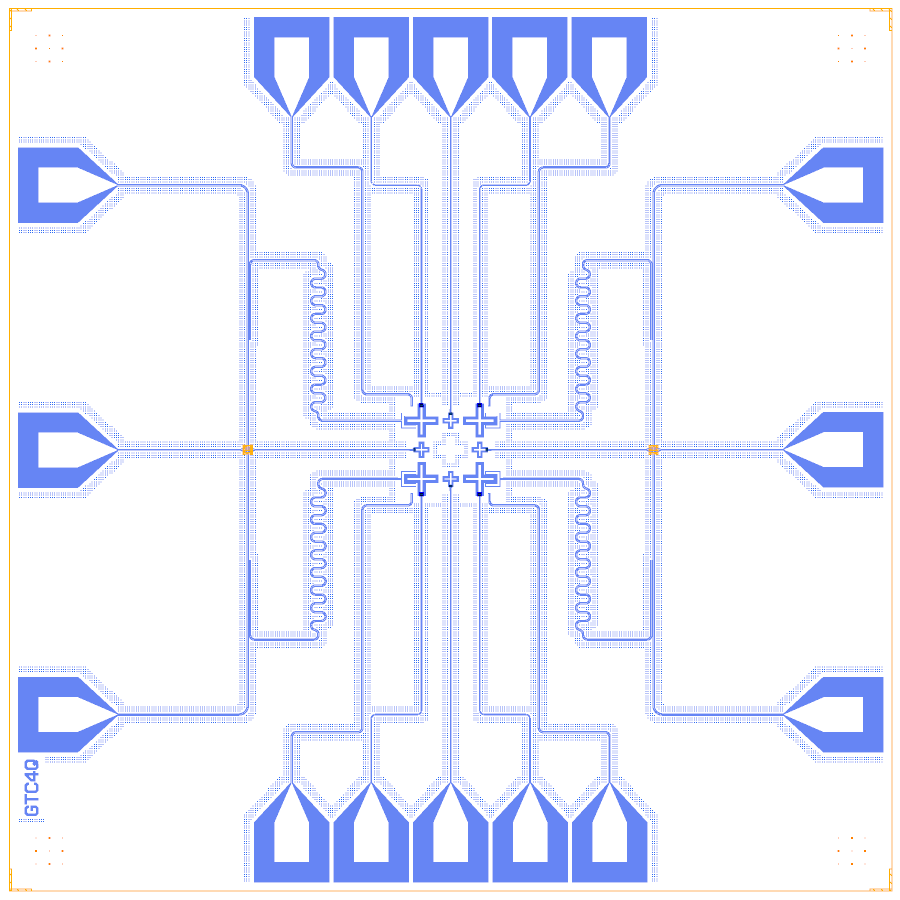

**On the chip so far:** 16 pads · 8 qubits · 4 other components · 18 routes · 14 declared couplings. **This step added** 4 component(s) `XY_Q00_end`, `XY_Q10_end`, `XY_Q01_end`, `XY_Q11_end` and 12 route(s) `XY_Q00_line`, `Z_Q00_line`, `XY_Q10_line`, `Z_Q10_line`, `XY_Q01_line`, `Z_Q01_line`, `XY_Q11_line`, `Z_Q11_line` … (+4).

WindowsPath('examples/designs/google/google_tc_2x2_s7_control.png')

In [13]:
# XY drive ends: an open CPW end at each qubit's outer diagonal
xy_end = {name: d.add(f"XY_{name}_end", "metal:OpenToGround", at=M(sx, sy)(X0 - S - 110, Y0 - S - 170),
                      rot=90 if sy < 0 else -90) for name, (sx, sy) in QUBITS.items()}
for name, (sx, sy) in QUBITS.items():
    m = M(sx, sy)
    d.route(f"XY_{name}_line", pads[f"XY_{name}"].a, xy_end[name].open, r=50,
            nodes=[m(3200, 1800), m(4000, 1800), m(4000, Y0 - S - 300), m(X0 - S - 110, Y0 - S - 300)])
    d.route(f"Z_{name}_line", q[name].flux_line, pads[f"Z_{name}"].a, r=50, nodes=[m(X0 - S, 2000), m(4100, 2000)])
for name, (qa, qb, (x, y), rot) in BONDS.items():
    if name in ("CB", "CT"):
        d.route(f"Z_{name}_line", tc[name].flux_line, pads[f"Z_{name}"].a, r=50)
    else:
        sx = -1 if name == "CL" else 1
        d.route(f"Z_{name}_line", tc[name].flux_line, pads[f"Z_{name}"].a, r=50,
                nodes=[d.waypoint(M(sx, -1)(XF, Y0), airbridge=True)])
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "google_tc_2x2_s7_control.png", size=(900, 900), width=320)

## Design 8 · The whole chip: centring check, targets, sim groups, save

`center_in_die(d)` measures the bounding box of all instances and routes and shifts them to centre it in the die; here
the plaquette was laid out round the die centre, so it returns (0, 0) (no shift within its 50 µm tolerance).

The targets are the source's; two sim groups define the FEM boxes: the `plaquette` (4 qubits, 4 couplers, the XY ends:
the C-matrix replaces every `d.couple` estimate) and `Q00_read` (Q00 with its readout).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (the feedlines and the readouts were added before the couplers and the XY / Z lines here; the v1 added each qubit's readout, XY and Z line together), so `git diff` stays empty.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/google/google_tc_2x2.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer google_tc_2x2: 28 instances, 18 routes, live=False> → examples\designs\google\google_tc_2x2.json


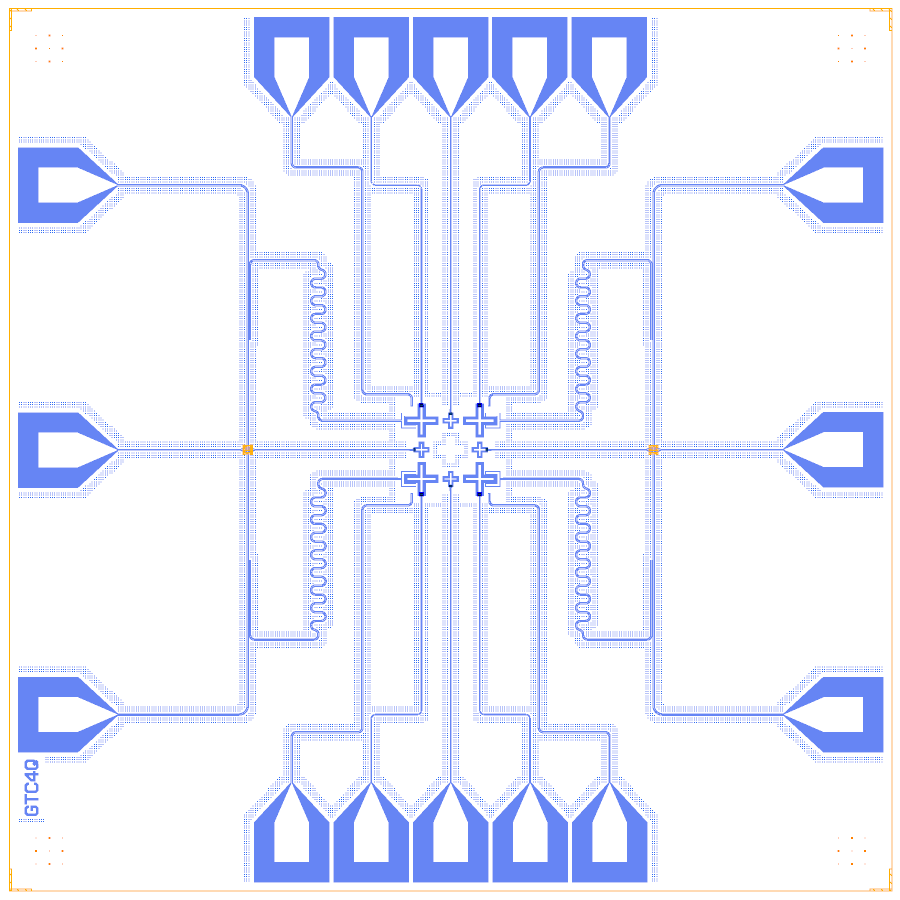

**On the chip so far:** 16 pads · 8 qubits · 4 other components · 18 routes · 14 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/google/google_tc_2x2_s8_chip.png')

In [14]:
print("centring shift (µm):", center_in_die(d))
d.targets(**{n: {"f_q_GHz": SRC["f_q_idle_GHz"], "alpha_MHz": SRC["alpha_MHz"]} for n in QUBITS},
          **{f"R_{n}": {"f_GHz": F_R[n], "kappa_MHz": SRC["kappa_MHz"]} for n in QUBITS})
d.sim_group("plaquette", list(QUBITS) + list(BONDS) + [f"XY_{n}_end" for n in QUBITS], margin_um=60,
            analyses=["q3d_cmatrix"])
d.sim_group("Q00_read", ["Q00", "R_Q00"], margin_um=60, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN, same = save_design(d, OUT / "google_tc_2x2.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "google_tc_2x2_s8_chip.png", size=(900, 900), width=320)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

- **errors:** none expected;
- **warnings:** `dangling_port` on the `squid_a` / `squid_b` junction attachment points of the eight crosses (the cell
  draws the trilayer SQUID itself), and four `overlap`s: each XY end sits inside its qubit's bounding box, at the outer
  diagonal of the cross, by design (zoom in Fab 2);
- **PDK design warnings:** none expected (every SQUID's parallel R_n ≈ 40 kΩ is in the window, Design 4; the f_q
  targets are in 4–8 GHz; every pad at 100 µm).

From the v1 run: **0 errors · 20 warnings (16 `dangling_port`, 4 `overlap`) · 0 PDK design warnings**; the drawn SQUID is
6.01 nH, parallel R_n 40.2 kΩ.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

Eight grounded islands with SQUIDs (4 qubits, 4 couplers), a claw node per qubit with its λ/4 readout `TLres` and
hanger κ into `FLL` / `FLR`, XY ends as 50 Ω drive ports, the Z lines as `flux_bias` controls; the `d.couple`
capacitances (qubit–coupler on every bond, the direct qubit–qubit capacitance across every coupler and the two
diagonals). The airbridges join the two halves of each side coupler's Z line (one conductor).

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed; targets in brackets; the couplers are outside these groups).
The λ/4 lengths were calibrated before the Nb film's kinetic inductance (PDK `kinetic`) entered the LOM;
with it every line is ≈ 1.6 % slower, so f_r lands ≈ 75 MHz below its target. Flagged, not retuned (values are not
the point of the rebuild). From the v1 run: f_q 6.6675 GHz (all four), α −236.5 MHz; f_r 4.4873 / 4.5269 /
4.5665 / 4.6055 GHz (Q00, Q01, Q10, Q11); κ 0.66–0.71 MHz; χ −0.17 … −0.21 MHz.

In [ ]:
read = {f"{n}+R": [n, f"R_{n}", "FLL" if n in ("Q00", "Q01") else "FLR"] for n in QUBITS}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))

**(b) Coupler sweep on the bottom bond (Q00–CB–Q10)**; the four bonds are the same geometry. As in `google_tc_cell`:
degenerate qubits → 2|g̃| from the dressed splitting, sign from Yan's Eq. 5; Q10 detuned by `DETUNE_LJ` for the
static ZZ. The v1 run gives the cell's numbers: g̃ +5.0 MHz at f_c,max (8.765 GHz), 0 at f_c ≈ 7.772 GHz
(L_J,c 7.56 nH, Φ ≈ 0.208 Φ0), −25.9 MHz at 6.943 GHz.

In [ ]:
LJ_C = [6.0, 6.5, 7.0, 7.25, 7.5, 7.75, 8.0, 8.5, 9.0, 9.25, 9.5]
DETUNE_LJ = 6.9
sweep = coupler_sweep(d, ["Q00", "CB", "Q10"], "Q00", "Q10", "CB", LJ_C, detune_lj=DETUNE_LJ)
display(Markdown(coupler_sweep_md(sweep)))
off = off_point(sweep)
display(Markdown(f"**Off point:** f_c ≈ {off['f_c_GHz']:.3f} GHz (L_J,c ≈ {off['lj_nH']:.2f} nH, Φ ≈ "
                 f"{off['flux_phi0']:.3f} Φ0)" if off else "**Off point:** not inside the sweep"))
plot_coupler_sweep(sweep, OUT / "google_tc_2x2_sweep.png", title="2 × 2 plaquette, bond Q00–CB–Q10 (LOM)")

**(c) The plaquette at idle, bond by bond**: every coupler at the off point, the qubits in a checkerboard (Q00 / Q11
at the design L_J, Q10 / Q01 at `DETUNE_LJ`), each bond (qubit – coupler – qubit) simulated with QuTiP: dressed
frequencies and the residual static ZZ of each neighbouring pair. (All eight junctions in one QuCat network exceed
its symbolic solver, so the plaquette is taken bond by bond; the two diagonals couple only through the 0.08 fF
estimate.) The junction values change in the LOM only and are put back afterwards.

From the v1 run: on every bond the qubits sit at 6.567 (Q00, Q11) and 6.119 GHz (Q10, Q01) and the coupler at 7.767 GHz;
the residual static ZZ of each neighbouring qubit pair is −88 kHz.

In [ ]:
lj_off = round(off["lj_nH"], 4) if off else LJ_C[0]
for n in BONDS:
    d[n].spec["junction"] = {**CJ, "Lj_nH": lj_off}             # couplers at the off point (LOM only)
for n in ("Q10", "Q01"):
    d[n].spec["junction"] = {**QJ, "Lj_nH": DETUNE_LJ}          # checkerboard detuning (LOM only)
idle = simulate_groups(d, {f"{qa}–{name}–{qb}": [qa, name, qb] for name, (qa, qb, _, _) in BONDS.items()},
                       max_modes=3)
for n in BONDS:
    d[n].spec["junction"] = dict(CJ)
for n in ("Q10", "Q01"):
    d[n].spec["junction"] = dict(QJ)
display(Markdown(groups_md(idle)))
display(Markdown(zz_md(idle)))

## LOM 2 · The LOM in two plots

The coupler sweep has its plot in LOM 1 (b). Here the pair and bond results as pictures: (a) every normal mode of each
simulated group (QuCat; circles are the qubits and couplers, squares the readouts; filled markers are the QuTiP
dressed values; red bars the targets), (b) the dispersive shift |χ| of each readout. From the v1 run the readouts sit
≈ 75 MHz below their red bars (the Nb kinetic inductance, LOM 1 a).

In [ ]:
plot_lom({**results, **idle}, OUT / "google_tc_2x2_lom.png", targets=d.data["targets"],
         title="google_tc_2x2: LOM, pairs and the bonds at idle")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The bottom coupler's arms go from 70 to 60 µm: a smaller cross has less capacitance, so its maximum frequency (and
|α_c|) rises and its pull on the qubits changes. The bond Q00–CB–Q10 is simulated with the coupler at zero flux and
Q10 detuned (`DETUNE_LJ`, as in LOM 1 c: degenerate qubits would hybridise), before and after. `design_copy` opens a
second, non-live Designer on the saved design; the design file stays as it is. From the v1 run: CB's f_c,max 8.754 → 9.151 GHz
and α_c −425 → −471 MHz; the qubits move by less than 1 MHz (Q00 6.5722 → 6.5727, Q10 6.1211 → 6.1213 GHz).

In [ ]:
bond = {"Q00–CB–Q10": ["Q00", "CB", "Q10"]}
d2 = design_copy(DESIGN)
d2["Q10"].spec["junction"] = {**QJ, "Lj_nH": DETUNE_LJ}      # detuned pair (LOM only)
before = simulate_groups(d2, bond, max_modes=3)
d2["CB"].set(cross_length=60)
after = simulate_groups(d2, bond, max_modes=3)
display(Markdown(params_delta_md(before, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/google/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Three jobs: a Q3D C-matrix job for the `plaquette` (4 qubits, 4 couplers, the XY ends) and, for `Q00_read`, a
C-matrix and an eigenmode job with its readout. Simulation exports draw the junctions as lumped lines and never carry
cheese; airbridges are left out unless `build_simulation(..., airbridges=True)`. Exporting again replaces a job folder,
results included.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/google/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["plaquette", "Q00_read"])
jobs_eig = export_sims(DESIGN, ["Q00_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

Two C-matrices: the `plaquette` (the eight islands and the four XY ends: it replaces every `d.couple` estimate) and
`Q00_read` (Q00 with its claw and readout). Each net is named after its LOM node, so the matrix goes straight into the
circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there
are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

`Q00_read` in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J sheet, the lines leaving the box end in 50 Ω, so each
mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's
energy participation p_J into dressed frequencies, α and χ. The airbridges are left out of FEM exports unless
`build_simulation(..., airbridges=True)`.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q00_read`: R_Q00 is a hanger on the left feedline; if the box cuts that
feedline (the job table above lists its ports), S21 between the two cut ends shows the notch (f_r and the external κ).

In [ ]:
f_r0 = results["Q00+R"].params.get("R_Q00.f_GHz")      # the LOM's readout frequency (LOM 1 a)
jobs_drv = driven_from_eigenmode(DESIGN, "Q00_read", jobs_eig["Q00_read"][0], keep_eig["Q00_read"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q00_read"]:
    display(Markdown(driven_md(keep_drv["Q00_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {"Q00_read": ("Q00", "R_Q00", "Q00+R")}  # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = results[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "google_tc_2x2_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q00_read"]:
    qb, rr, _ = PAIRS["Q00_read"]
    fem_values.setdefault("Q00_read", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q00_read"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of R_Q00.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

Below the table: the bottom bond Q00–CB–Q10 on the `plaquette` C-matrix (all three at their
design junctions, the coupler at zero flux), once that job is kept: its normal modes with the extracted
qubit–coupler and qubit–qubit capacitances in place of the estimates.

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = results[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=read[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

BOND = ["Q00", "CB", "Q10"]
if keep_q3d.get("plaquette"):
    bond_fem = simulate(fill(d.lom(select=BOND).model, DESIGN, keep_q3d["plaquette"]), max_modes=3)
    display(Markdown("**Q00–CB–Q10 on the plaquette C-matrix, QuCat normal modes:**\n\n" + modes_md(bond_fem)))

## Results 4 · Feedback: one step towards the targets

The design carries the source's targets (Design 8): every qubit at Sycamore's idle 6.661 GHz with α −208 MHz, the
four readouts at 4.56–4.68 GHz with κ 0.64 MHz. **α stays out of the feedback copy**, as in `google_tc_cell`: with the
PDK window (R_n ≥ 40 kΩ caps E_J) a cross at 6.66 GHz has the larger E_C, so −208 MHz is out of reach inside it
(−237 MHz from the v1 run). `target_copy(DESIGN, TARGETS)` writes the design with each qubit's target set to f_q only
(the readouts keep f_r and κ) to `build/google_tc_2x2_target.json`; the design file keeps all of the source's targets.
From the v1 run f_q is on target (6.6675 GHz) and the readouts ≈ 1.6 % low (4.487–4.606 GHz), so the feedback
shortens the four readouts by about that much (their paths are far shorter than their 6.1–6.2 mm).

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on each qubit–readout pair of the circuit
— four here, so it takes minutes; the couplers have no readout, so they are not pairs — on the Q3D values where a solve
was kept, and picks one value per quantity (the consensus). `loop.feedback` anchors a surrogate on that point and
proposes the knobs that put the targets inside their tolerances (f_q ± 20 MHz, f_r ± 10 MHz, κ ± 0.2 MHz); the
proposal is written as revision 1, built and netlist-checked. `pdk_lj_bounds` keeps the SQUIDs inside the 40–50 kΩ
window (they sit at its low end).

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {q: {"f_q_GHz": SRC["f_q_idle_GHz"]} for q in QUBITS}   # f_q only: α is out of the PDK window's reach
DESIGN_T = target_copy(DESIGN, TARGETS)          # the readouts keep the design's f_r and κ targets
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/google_tc_2x2/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the `Q00_read` Q3D job are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q00_read Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q00_read",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "google_tc_2x2_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `examples/designs/google/google_tc_2x2.json` (Design 8); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists; 22 733 holes in the v1 run); the airbridges go to 300/0 + 301/0.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps the airbridges
  in a FEM export; cheese never.
- **The same from the command line:** `qcc build examples/designs/google/google_tc_2x2.json`, `qcc design drc …`,
  `qcc mask …`, `qcc sim build … -g plaquette -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die (16 pads, two vertical feedlines, four λ/4 meanders, the plaquette in the centre, QCT device ID); the
plaquette (four crosses and four small couplers, every SQUID arm pointing outwards, the claws and XY ends); a coupler's
SQUID; the left coupler's Z line crossing the left feedline on its airbridge; and the fab mask round the plaquette (the
PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0 and 3/0, the junction layers).

In [ ]:
snap(d, OUT / "google_tc_2x2.png", size=(1500, 1500))
snap(d, OUT / "google_tc_2x2_plaquette.png", box=(X0 - S - 450, Y0 - S - 450, X0 + S + 450, Y0 + S + 450),
     size=(1400, 1400), width=560)
snap(d, OUT / "google_tc_2x2_squid.png", box=(X0 - 40, Y0 - S - 125, X0 + 40, Y0 - S - 55), size=(800, 700), width=320)
snap(d, OUT / "google_tc_2x2_bridge.png", box=(XF - 120, Y0 - 90, XF + 120, Y0 + 90), size=(1000, 750), width=360)
snap_file(Path("build") / "google_tc_2x2_fab.oas", OUT / "google_tc_2x2_cheese.png",
          box=(X0 - S - 450, Y0 - S - 450, X0 + S + 450, Y0 + S + 450), size=(1000, 1000), width=400);

## Summary

- **Matches the source:** the plaquette topology (a tunable coupler on every bond), the cell's off point on every bond
  (f_c ≈ 7.77 GHz), the idle ZZ below 0.1 MHz, f_q at Sycamore's idle, the staggered readouts (≈ 1.6 % below
  their targets: Nb kinetic inductance now in the LOM, LOM 1 a; from the v1 run).
- **Changed by the PDK:** trilayer SQUIDs at R_n ≈ 40 kΩ (α −237 MHz, Sycamore −208 MHz); the 10 mm die and frame;
  pads 100 µm from the edges (the hangers placed by position, `near=`); the PDK band cheese (no original exists); planar wiring with two airbridges instead of
  Sycamore's flip-chip.
- **Open PDK design warnings:** none (every SQUID's parallel R_n 40.2 kΩ is in the window).
- **Known limits:** the plaquette is simulated bond by bond (QuCat's symbolic solver stops at 8 junctions); the
  coupling capacitances are CPS estimates until the `plaquette` Q3D job has run.
- **Layout:** built in segments (die, pads, the feedlines, the qubits, the readouts, the couplers and their couplings, the XY / Z lines, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards the source's f_q and readout targets on a copy (α left out: out of the PDK window's reach): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`), PDK L_J bounds.
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.